# Loading Libraries

In [30]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import sklearn.datasets
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import seaborn as sns
import torch
import torch.nn as nn

# Data Collection and Preprocessing

In [31]:
breast_cancer_detection = sklearn.datasets.load_breast_cancer()

In [32]:
breast_cancer_detection 

{'data': array([[1.799e+01, 1.038e+01, 1.228e+02, ..., 2.654e-01, 4.601e-01,
         1.189e-01],
        [2.057e+01, 1.777e+01, 1.329e+02, ..., 1.860e-01, 2.750e-01,
         8.902e-02],
        [1.969e+01, 2.125e+01, 1.300e+02, ..., 2.430e-01, 3.613e-01,
         8.758e-02],
        ...,
        [1.660e+01, 2.808e+01, 1.083e+02, ..., 1.418e-01, 2.218e-01,
         7.820e-02],
        [2.060e+01, 2.933e+01, 1.401e+02, ..., 2.650e-01, 4.087e-01,
         1.240e-01],
        [7.760e+00, 2.454e+01, 4.792e+01, ..., 0.000e+00, 2.871e-01,
         7.039e-02]], shape=(569, 30)),
 'target': array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 1, 1,
        0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0,
        0, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0, 1, 0, 0, 1, 1, 1, 1, 0, 1, 0, 0,
        1, 1, 1, 1, 0, 1, 0, 0, 1, 0, 1, 0, 0, 1, 1, 1, 0, 0, 1, 0, 0, 0,
        1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 1,
        1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 1,

## Convert to a DataFrame

In [33]:
df = pd.DataFrame(breast_cancer_detection.data, columns=breast_cancer_detection.feature_names)
df["label"] = breast_cancer_detection.target
df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,label
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


## Explore the data

In [34]:
df.shape

(569, 31)

In [35]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         569 non-null

In [36]:
df.isnull().sum()

mean radius                0
mean texture               0
mean perimeter             0
mean area                  0
mean smoothness            0
mean compactness           0
mean concavity             0
mean concave points        0
mean symmetry              0
mean fractal dimension     0
radius error               0
texture error              0
perimeter error            0
area error                 0
smoothness error           0
compactness error          0
concavity error            0
concave points error       0
symmetry error             0
fractal dimension error    0
worst radius               0
worst texture              0
worst perimeter            0
worst area                 0
worst smoothness           0
worst compactness          0
worst concavity            0
worst concave points       0
worst symmetry             0
worst fractal dimension    0
label                      0
dtype: int64

In [37]:
df.describe()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,label
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000


# Exploratory Data Analysis (EDA)

## Class balance

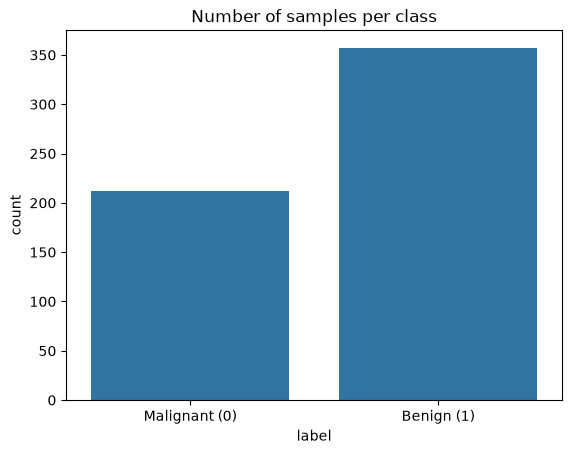

In [38]:
sns.countplot(x="label", data=df)
plt.xticks([0, 1], ["Malignant (0)", "Benign (1)"])
plt.title("Number of samples per class")
plt.show()

## Distribution of the mean features

Histograms show the spread of each feature for both classes.

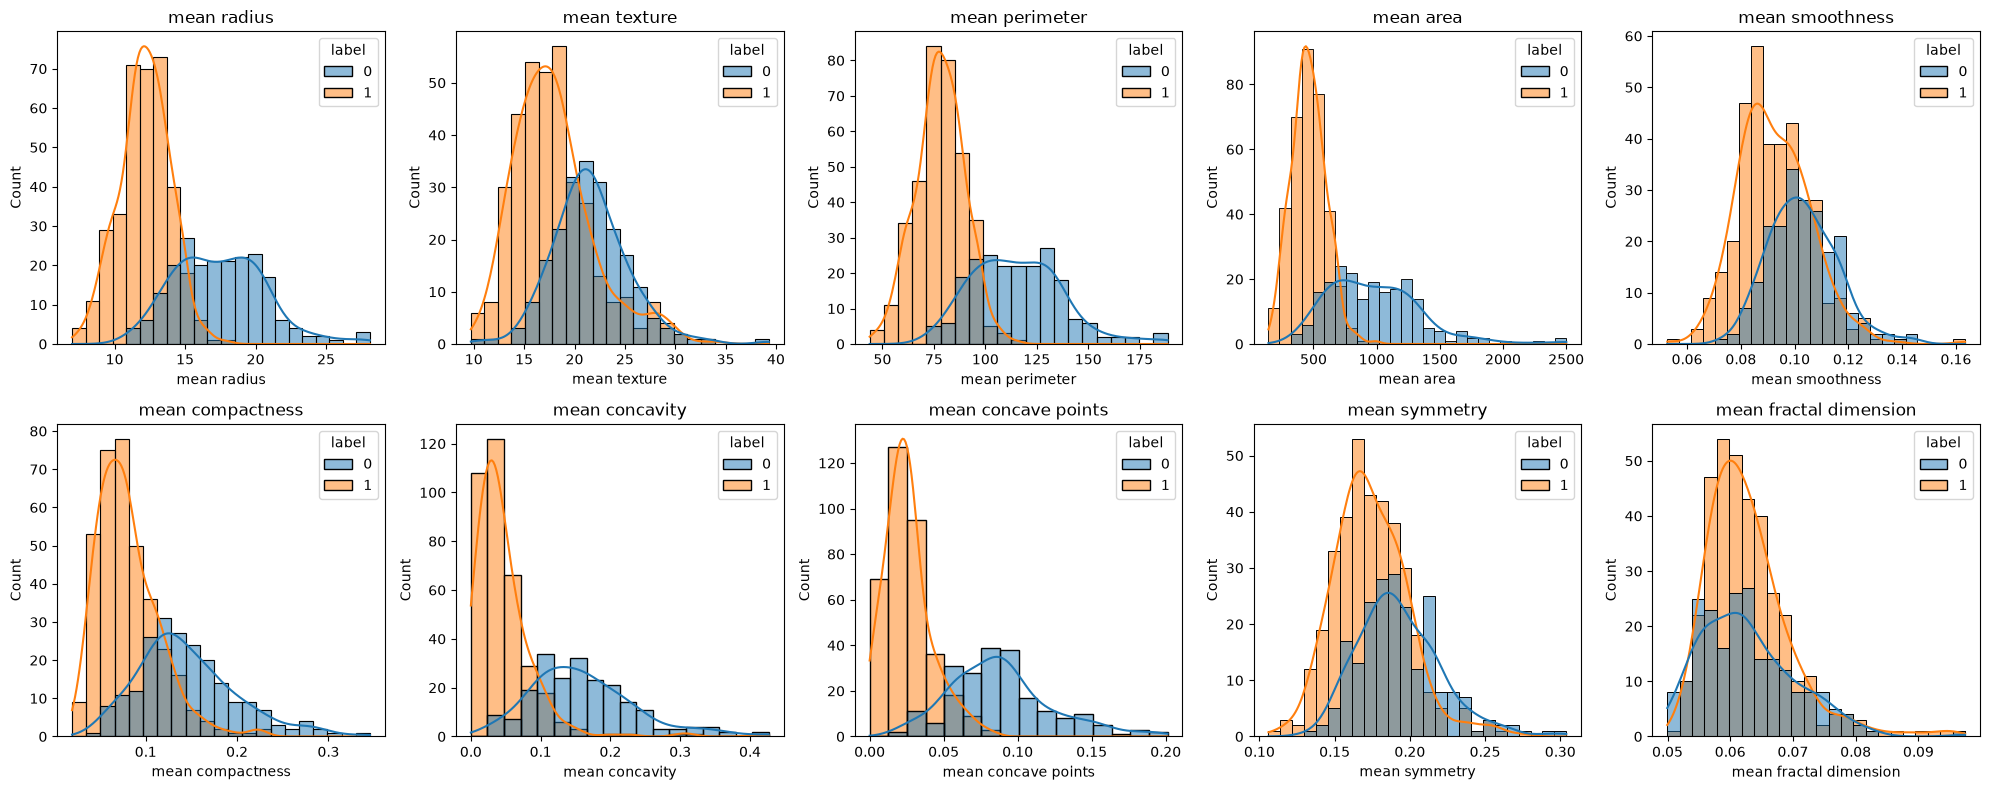

In [39]:
mean_features = list(df.columns[:10])

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, feature in zip(axes.flat, mean_features):
    sns.histplot(data=df, x=feature, hue="label", kde=True, ax=ax)
    ax.set_title(feature)
plt.tight_layout()
plt.show()

## Feature values by class

Box plots make it easy to see which features separate malignant from benign tumours.

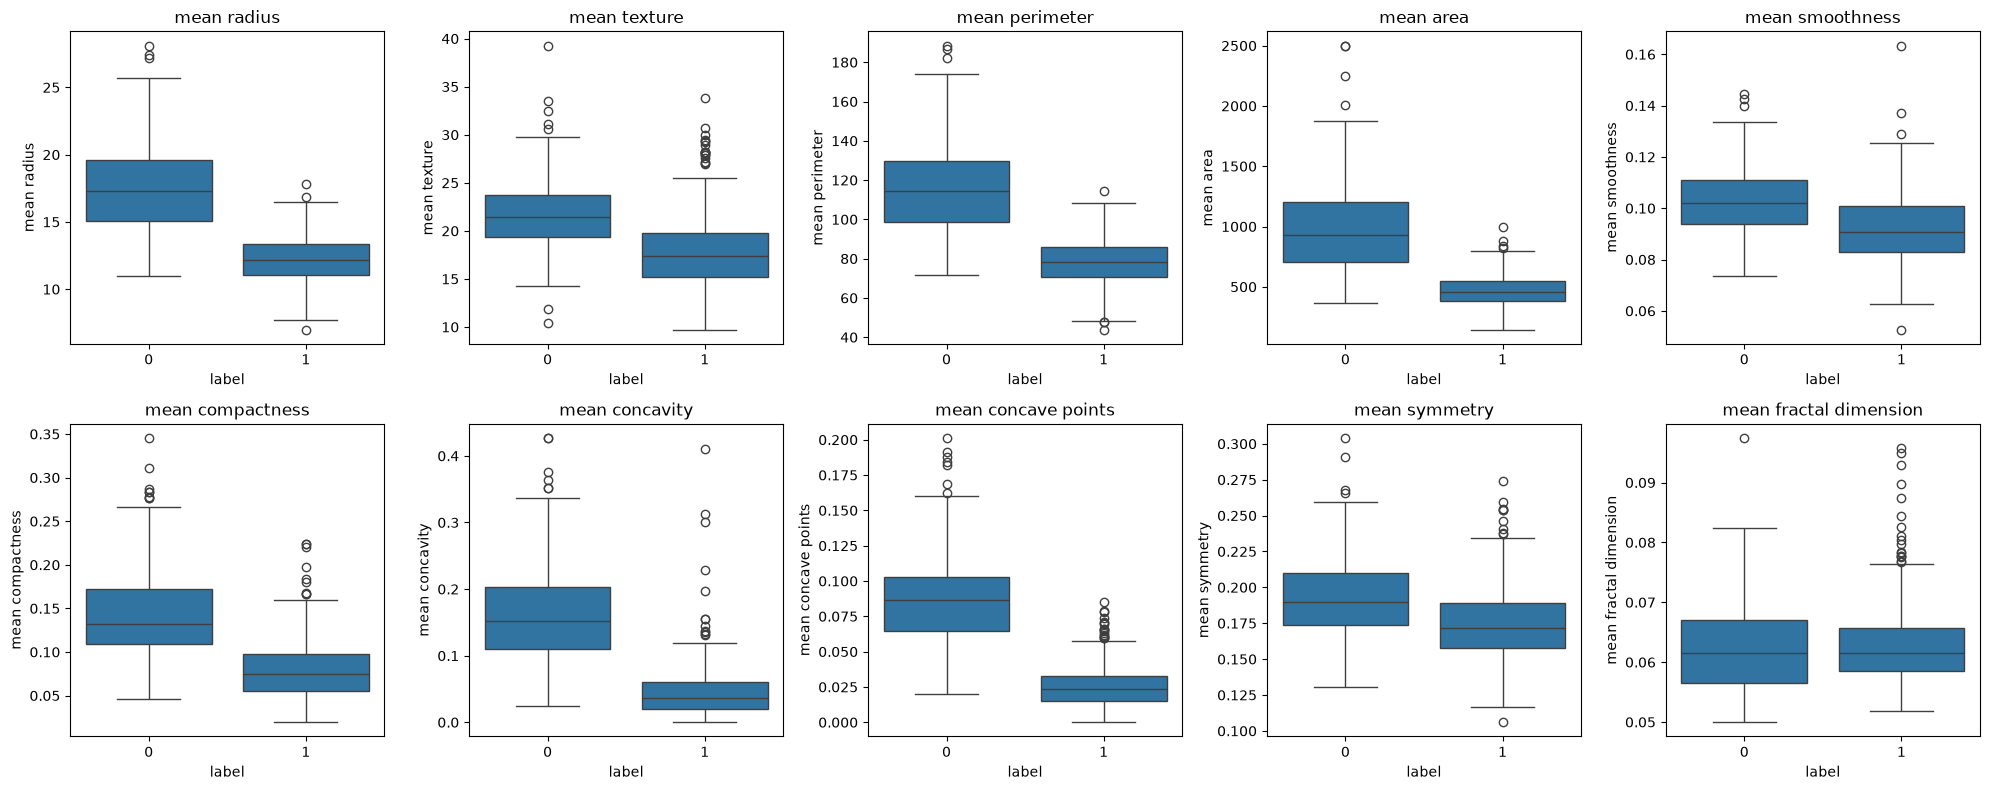

In [40]:
fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for ax, feature in zip(axes.flat, mean_features):
    sns.boxplot(data=df, x="label", y=feature, ax=ax)
    ax.set_title(feature)
plt.tight_layout()
plt.show()

## Correlation between features

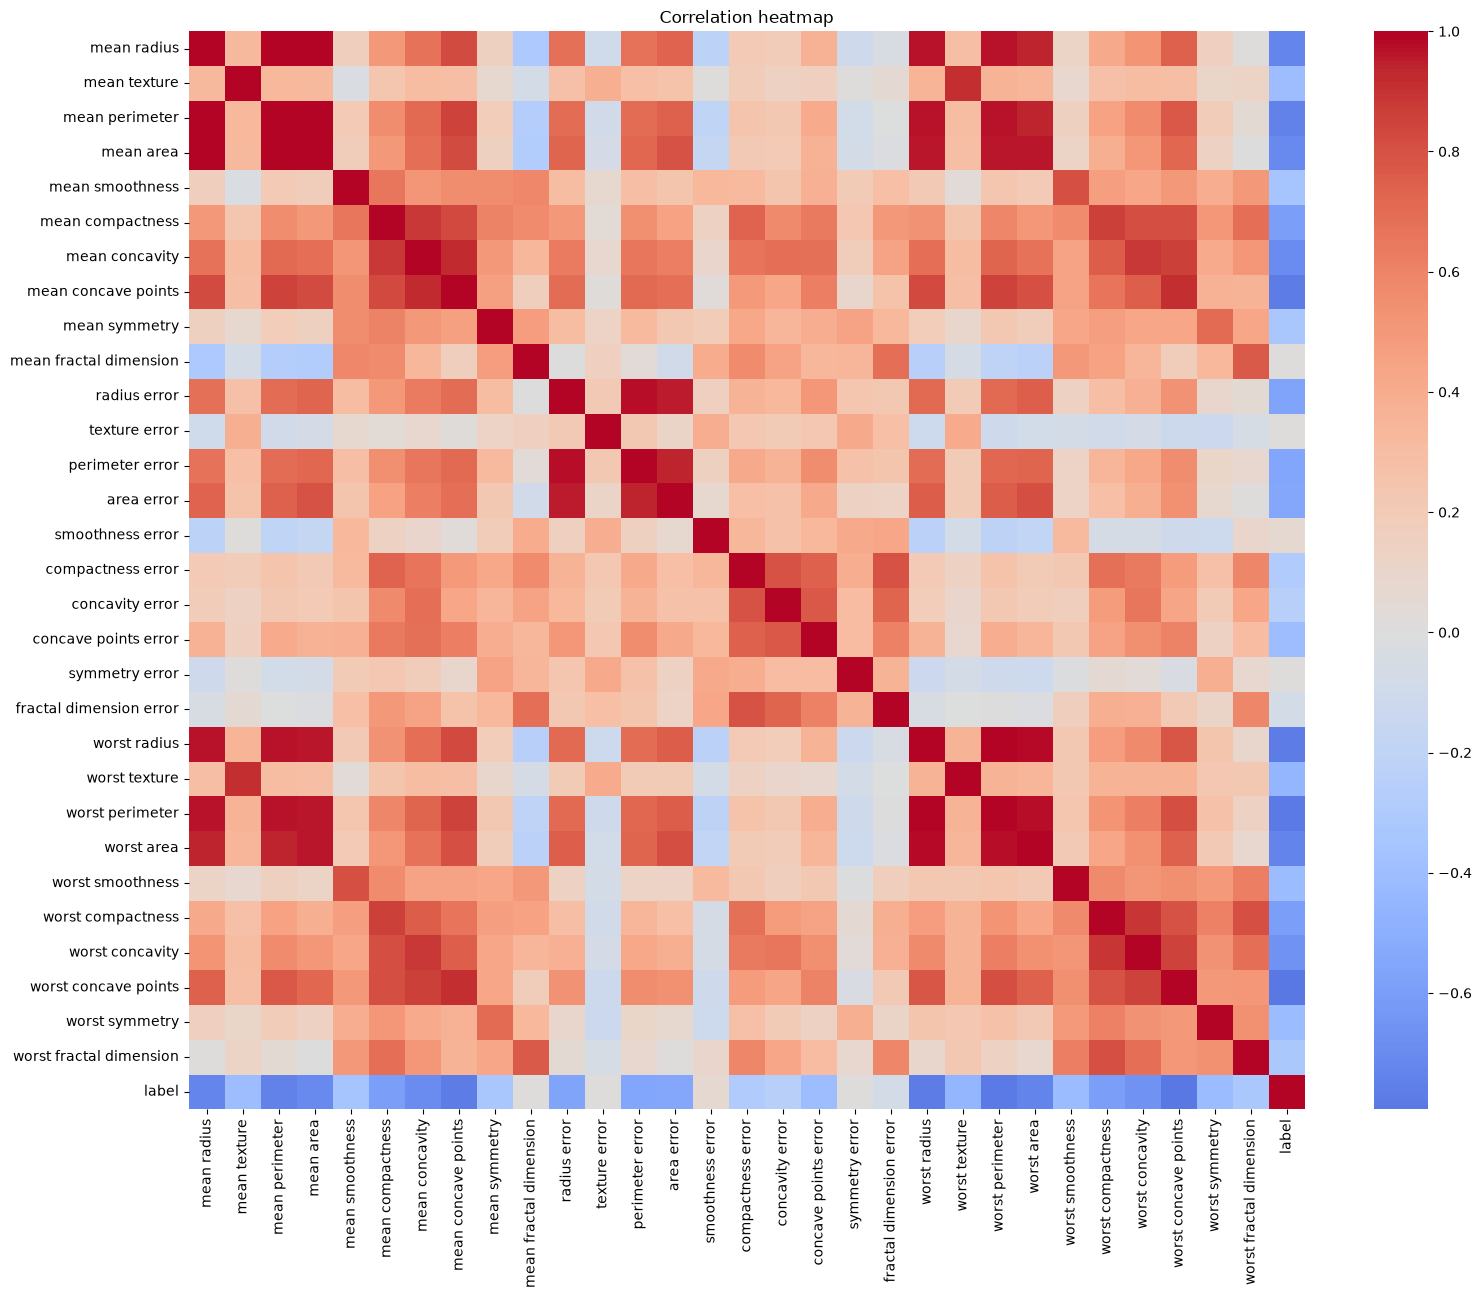

In [41]:
plt.figure(figsize=(18, 14))
sns.heatmap(df.corr(), cmap="coolwarm", center=0)
plt.title("Correlation heatmap")
plt.show()

## Features most correlated with the label

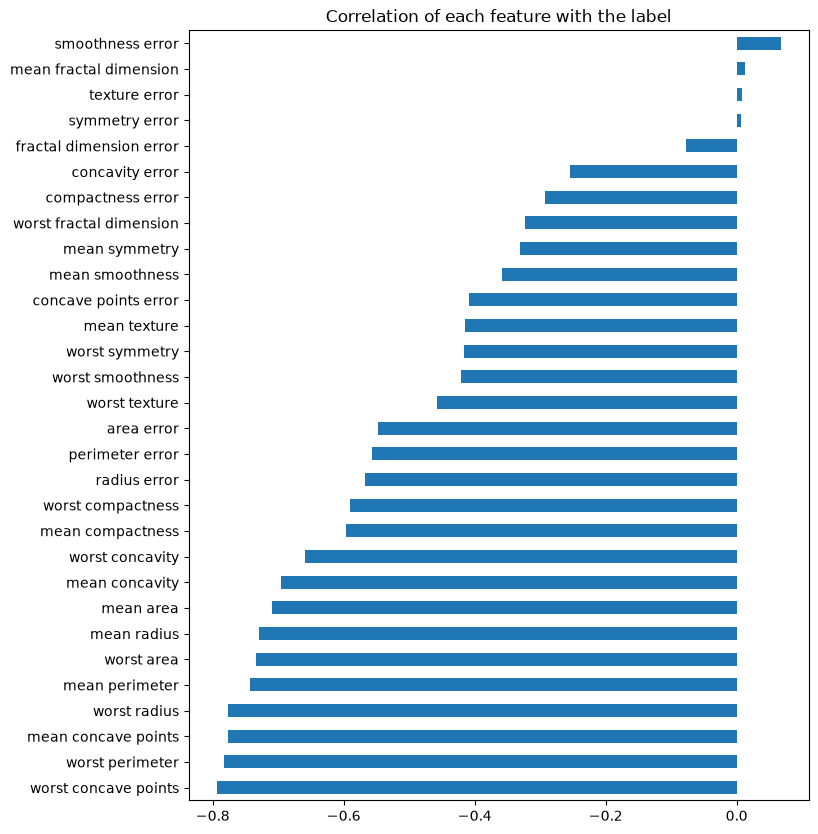

In [42]:
df.corr()["label"].drop("label").sort_values().plot(kind="barh", figsize=(8, 10))
plt.title("Correlation of each feature with the label")
plt.show()

## Target distribution

- `0` = Malignant
- `1` = Benign

In [43]:
df["label"].value_counts()

label
1    357
0    212
Name: count, dtype: int64

In [44]:
df.groupby("label").mean()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst radius,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension
label,,,,,,,,,,,,,,,,,,,,,
0,17.462830,21.604906,115.365377,978.376415,0.102898,0.145188,0.160775,0.087990,0.192909,0.062680,...,21.134811,29.318208,141.370330,1422.286321,0.144845,0.374824,0.450606,0.182237,0.323468,0.091530
1,12.146524,17.914762,78.075406,462.790196,0.092478,0.080085,0.046058,0.025717,0.174186,0.062867,...,13.379801,23.515070,87.005938,558.899440,0.124959,0.182673,0.166238,0.074444,0.270246,0.079442


## Separate features and target

In [45]:
X = df.drop(columns="label")
y = df["label"]

## Split into training and test sets

In [46]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=2
)

print(X.shape, X_train.shape, X_test.shape)

(569, 30) (455, 30) (114, 30)


## Feature scaling

Fit the scaler on the training data only, so no information from the test set leaks into training.

In [47]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Neural Network with PyTorch

We start with a simple network: **30 inputs → 16 hidden units (ReLU) → 1 output**.

The output is a raw score (logit). `BCEWithLogitsLoss` applies the sigmoid internally, and we apply it ourselves only when making predictions.

## Convert data to tensors

In [48]:
torch.manual_seed(42)

X_train_t = torch.tensor(X_train, dtype=torch.float32)
X_test_t = torch.tensor(X_test, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.float32).unsqueeze(1)
y_test_t = torch.tensor(y_test.values, dtype=torch.float32).unsqueeze(1)

print(X_train_t.shape, y_train_t.shape)

torch.Size([455, 30]) torch.Size([455, 1])


## Define the model

In [49]:
class SimpleNN(nn.Module):                     
    def __init__(self, input_size):            # input_size = number of features (30)
        super().__init__()                     # Initialise the parent nn.Module
        self.network = nn.Sequential(          # Layers run one after another, in this order
            nn.Linear(input_size, 16),         # Hidden layer: 30 inputs -> 16 neurons
            nn.ReLU(),                         # Activation: keeps positives, turns negatives to 0
            nn.Linear(16, 1),                  # Output layer: 16 neurons -> 1 score (logit)
        )

    def forward(self, x):                      
        return self.network(x)                 

model = SimpleNN(input_size=X_train_t.shape[1])  
model                                            

SimpleNN(
  (network): Sequential(
    (0): Linear(in_features=30, out_features=16, bias=True)
    (1): ReLU()
    (2): Linear(in_features=16, out_features=1, bias=True)
  )
)

## Loss function and optimizer

In [50]:
loss_fn = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

## Train the model

In [51]:
epochs = 100
train_losses, test_losses = [], []

for epoch in range(epochs):
    # Training step
    model.train()
    optimizer.zero_grad()
    loss = loss_fn(model(X_train_t), y_train_t)
    loss.backward()
    optimizer.step()

    # Evaluation on the test set
    model.eval()
    with torch.no_grad():
        test_loss = loss_fn(model(X_test_t), y_test_t)

    train_losses.append(loss.item())
    test_losses.append(test_loss.item())

    if (epoch + 1) % 10 == 0:
        print(f"Epoch {epoch + 1:3d} | Train loss: {loss.item():.4f} | Test loss: {test_loss.item():.4f}")

Epoch  10 | Train loss: 0.2868 | Test loss: 0.2197
Epoch  20 | Train loss: 0.1296 | Test loss: 0.0804
Epoch  30 | Train loss: 0.0832 | Test loss: 0.0642
Epoch  40 | Train loss: 0.0655 | Test loss: 0.0647
Epoch  50 | Train loss: 0.0557 | Test loss: 0.0620
Epoch  60 | Train loss: 0.0501 | Test loss: 0.0610
Epoch  70 | Train loss: 0.0453 | Test loss: 0.0600
Epoch  80 | Train loss: 0.0413 | Test loss: 0.0609
Epoch  90 | Train loss: 0.0376 | Test loss: 0.0631
Epoch 100 | Train loss: 0.0347 | Test loss: 0.0652


## Loss curves

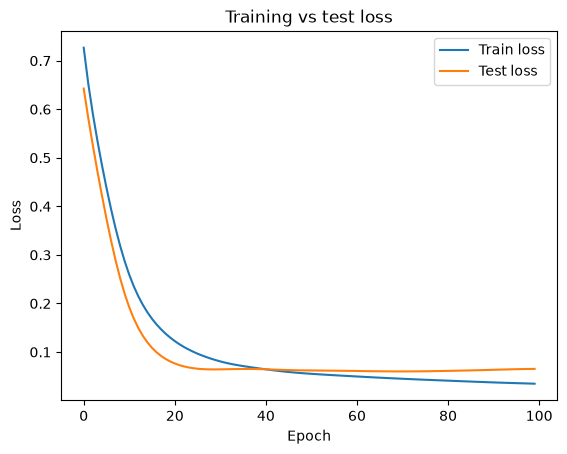

In [52]:
plt.plot(train_losses, label="Train loss")
plt.plot(test_losses, label="Test loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs test loss")
plt.legend()
plt.show()

## Evaluate accuracy

In [53]:
def accuracy(model, X, y):
    model.eval()
    with torch.no_grad():
        predictions = (torch.sigmoid(model(X)) > 0.5).float()
    return (predictions == y).float().mean().item()


print(f"Train accuracy: {accuracy(model, X_train_t, y_train_t):.4f}")
print(f"Test accuracy:  {accuracy(model, X_test_t, y_test_t):.4f}")

Train accuracy: 0.9912
Test accuracy:  0.9825
